# Medellín — Gaussian-Smoothed Edge Betweenness Filtration

Persistent homology where edges are added from **most important** (highest betweenness) to **least important** (lowest betweenness) in 10 equal steps.

This version first applies a **Gaussian filter on the edge-line graph**: each edge betweenness value is replaced by a Gaussian-weighted average of nearby edge betweenness values, where distance is measured in edge-adjacency hops. This smooths abrupt edge-to-edge jumps before the logarithmic importance filtration is assigned.

- All nodes are present from step 0.
- Edges are sorted by smoothed, normalised betweenness (descending) and split into 10 logarithmic bins.
- Step 1 adds the highest smoothed-betweenness edges; step 10 adds the lowest smoothed-betweenness edges.


In [18]:
import osmnx as ox
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import gudhi
from pathlib import Path

def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "edge_importance_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")

REPO_ROOT = find_repo_root()
EDGE_IMPORTANCE_ROOT = REPO_ROOT / "edge_importance_ph"
ROAD_IMPORTANCE_DIR = EDGE_IMPORTANCE_ROOT / "calculate_road_importance"

GRAPHML_PATH = ROAD_IMPORTANCE_DIR / "experiment_bounding_city" / "graphs" / "osmnx" / "sur_" / "America" / "medellin.graphml"
N_STEPS = 10

# Gaussian smoothing parameters on the edge-line graph.
# Distance is measured in edge-adjacency hops: two edges are distance 1
# if they share an endpoint in the undirected street graph.
GAUSSIAN_SIGMA_HOPS = 1.0
GAUSSIAN_RADIUS_HOPS = 1

# Load with OSMnx so the graph retains all OSMnx metadata
G = ox.load_graphml(GRAPHML_PATH)
G_undir = ox.convert.to_undirected(G)

print(f"Directed   — nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")
print(f"Undirected — nodes: {G_undir.number_of_nodes()}, edges: {G_undir.number_of_edges()}")
print(f"Gaussian smoothing — sigma={GAUSSIAN_SIGMA_HOPS} edge hops, radius={GAUSSIAN_RADIUS_HOPS} edge hops")


Directed   — nodes: 28729, edges: 65651
Undirected — nodes: 28729, edges: 39928
Gaussian smoothing — sigma=1.0 edge hops, radius=1 edge hops


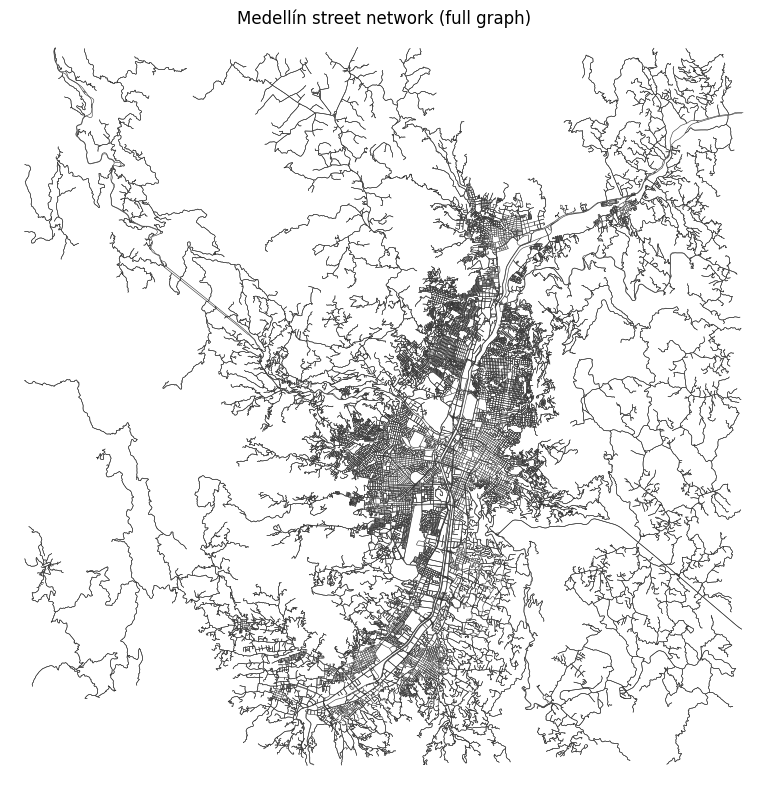

In [19]:
# ------------------------------------------------------------------
# Plot the full graph with OSMnx for a nice overview
# ------------------------------------------------------------------
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    edge_color="#333333",
    show=False,
    close=False,
)
ax.set_title("Medellín street network (full graph)", fontsize=12)
plt.tight_layout()
#plt.savefig("mde_full_graph.pdf")
plt.show()

In [20]:
# ------------------------------------------------------------------
# Extract betweenness values from edge attributes.
# The graphml stores betweenness as a string; convert to float.
# Edges without the attribute get betweenness = 0.
# ------------------------------------------------------------------
edge_records = []
raw_values = []

for u, v, data in G_undir.edges(data=True):
    val = data.get("heat_betweenness", 0)
    try:
        b = float(val)
    except (ValueError, TypeError):
        b = 0.0
    edge_records.append((u, v, data, b))
    raw_values.append(b)

raw_values = np.array(raw_values, dtype=float)
print(f"Betweenness — min: {raw_values.min():.6f}, max: {raw_values.max():.6f}, mean: {raw_values.mean():.6f}")
print(f"Edges with betweenness > 0: {(raw_values > 0).sum()} / {len(raw_values)}")


Betweenness — min: 0.000000, max: 155895528.000000, mean: 1115115.088434
Edges with betweenness > 0: 39899 / 39928


In [21]:
# ------------------------------------------------------------------
# Gaussian smooth the edge betweenness signal on the edge-line graph.
#
# For each edge e, collect all edges within GAUSSIAN_RADIUS_HOPS in
# the line graph. The smoothed value is:
#
#     sum_j exp(-d(e,j)^2 / (2*sigma^2)) * betweenness_j
#     --------------------------------------------------------
#     sum_j exp(-d(e,j)^2 / (2*sigma^2))
#
# This keeps the graph topology intact while removing abrupt local
# jumps in edge importance.
# ------------------------------------------------------------------
def gaussian_smooth_edge_values(graph, edge_records, values, sigma_hops=1.25, radius_hops=None):
    if radius_hops is None:
        radius_hops = int(np.ceil(3 * sigma_hops))
    if sigma_hops <= 0:
        raise ValueError("sigma_hops must be positive")

    edges = [(u, v) for u, v, _, _ in edge_records]
    incident_edges = {node: [] for node in graph.nodes()}
    for i, (u, v) in enumerate(edges):
        incident_edges[u].append(i)
        incident_edges[v].append(i)

    smoothed = np.empty_like(values, dtype=float)
    for i, (u, v) in enumerate(edges):
        distances = {i: 0}
        frontier = {i}

        for dist in range(1, radius_hops + 1):
            next_frontier = set()
            for edge_idx in frontier:
                a, b = edges[edge_idx]
                for node in (a, b):
                    for nbr_edge_idx in incident_edges[node]:
                        if nbr_edge_idx not in distances:
                            distances[nbr_edge_idx] = dist
                            next_frontier.add(nbr_edge_idx)
            frontier = next_frontier
            if not frontier:
                break

        idx = np.fromiter(distances.keys(), dtype=int)
        d = np.fromiter(distances.values(), dtype=float)
        weights = np.exp(-(d ** 2) / (2 * sigma_hops ** 2))
        smoothed[i] = np.dot(weights, values[idx]) / weights.sum()

    return smoothed


smoothed_values = gaussian_smooth_edge_values(
    G_undir,
    edge_records,
    raw_values,
    sigma_hops=GAUSSIAN_SIGMA_HOPS,
    radius_hops=GAUSSIAN_RADIUS_HOPS,
)

# Use the smoothed signal for the logarithmic importance filtration.
filtration_values = smoothed_values

print(f"Smoothed betweenness — min: {smoothed_values.min():.6f}, max: {smoothed_values.max():.6f}, mean: {smoothed_values.mean():.6f}")
print(f"Mean absolute smoothing change: {np.mean(np.abs(smoothed_values - raw_values)):.6f}")
print(f"Correlation raw vs smoothed: {np.corrcoef(raw_values, smoothed_values)[0, 1]:.4f}")


Smoothed betweenness — min: 13703.862119, max: 105309700.109685, mean: 1133543.373776
Mean absolute smoothing change: 639447.709092
Correlation raw vs smoothed: 0.8870


In [22]:
# ------------------------------------------------------------------
# Assign filtration steps using a REFINED equal-width log-scale scheme.
#
# Base: N_STEPS equal-width bins on log1p(smoothed betweenness), descending
# (step 1 = highest smoothed betweenness).
#
# Refinement: the top 2 base bins are each split into 2 finer sub-bins,
# giving steps 1-4 double resolution over the high-betweenness backbone.
# Steps 5-10 cover the remaining 6 base bins unchanged.
# Total steps remains N_STEPS = 10.
# ------------------------------------------------------------------
log_values = np.log1p(filtration_values)

log_max = log_values.max()
log_min = log_values.min()

base_width = (log_max - log_min) / N_STEPS   # width of one base bin
top2_lo    = log_max - 2 * base_width         # lower edge of the top-2 base bins

# 4 fine sub-bins inside the top-2 region
fine_edges   = np.linspace(top2_lo, log_max, 0)   # 5 pts -> 4 bins
# 6 coarse bins covering [log_min, top2_lo]
coarse_edges = np.linspace(log_min, top2_lo, 11)   # 7 pts -> 6 bins

# Combined: 7 + 4 = 11 points -> 10 bins, total steps = 10
all_edges = np.concatenate([coarse_edges, fine_edges[1:]])
assert len(all_edges) == N_STEPS + 1, f"Expected {N_STEPS+1} edges, got {len(all_edges)}"

def assign_step(log_b):
    """Return filtration step 1..N_STEPS (1 = most important)."""
    for step in range(1, N_STEPS + 1):
        lo = all_edges[N_STEPS - step]
        if log_b >= lo:
            return step
    return N_STEPS

# Build undirected graph H with filtration attribute on each edge
H = nx.Graph()
H.add_nodes_from(G_undir.nodes())

for (u, v, data, raw_b), smooth_b, log_b in zip(edge_records, smoothed_values, log_values):
    step = assign_step(log_b)
    if H.has_edge(u, v):
        if step < H[u][v]["filtration"]:
            H[u][v]["filtration"] = step
            H[u][v]["betweenness"] = raw_b
            H[u][v]["betweenness_smooth"] = smooth_b
    else:
        H.add_edge(u, v, filtration=step, betweenness=raw_b, betweenness_smooth=smooth_b)

print(f"H — nodes: {H.number_of_nodes()}, edges: {H.number_of_edges()}")
print("Steps 1-4 = top-2 smoothed log-betweenness bins split in half (fine resolution)")
print("Steps 5-10 = remaining 6 smoothed log-betweenness bins (coarse resolution)")

from collections import Counter
step_counts = Counter(d["filtration"] for _, _, d in H.edges(data=True))
print("\nEdges per filtration step:")
for s in range(1, N_STEPS + 1):
    lo  = np.expm1(all_edges[N_STEPS - s])
    hi  = np.expm1(all_edges[N_STEPS - s + 1])
    tag = "(fine)"   if s <= 4 else "(coarse)"
    print(f"  Step {s:2d}: {step_counts.get(s, 0):5d} edges  smoothed betweenness [{lo:.0f}, {hi:.0f}] {tag}")


H — nodes: 28729, edges: 39773
Steps 1-4 = top-2 smoothed log-betweenness bins split in half (fine resolution)
Steps 5-10 = remaining 6 smoothed log-betweenness bins (coarse resolution)

Edges per filtration step:
  Step  1:   805 edges  smoothed betweenness [8600072, 17593393] (fine)
  Step  2:  1407 edges  smoothed betweenness [4203921, 8600072] (fine)
  Step  3:  2821 edges  smoothed betweenness [2054977, 4203921] (fine)
  Step  4:  4367 edges  smoothed betweenness [1004521, 2054977] (fine)
  Step  5:  6017 edges  smoothed betweenness [491034, 1004521] (coarse)
  Step  6:  7067 edges  smoothed betweenness [240029, 491034] (coarse)
  Step  7:  7205 edges  smoothed betweenness [117331, 240029] (coarse)
  Step  8:  7321 edges  smoothed betweenness [57354, 117331] (coarse)
  Step  9:  2512 edges  smoothed betweenness [28035, 57354] (coarse)
  Step 10:   251 edges  smoothed betweenness [13704, 28035] (coarse)


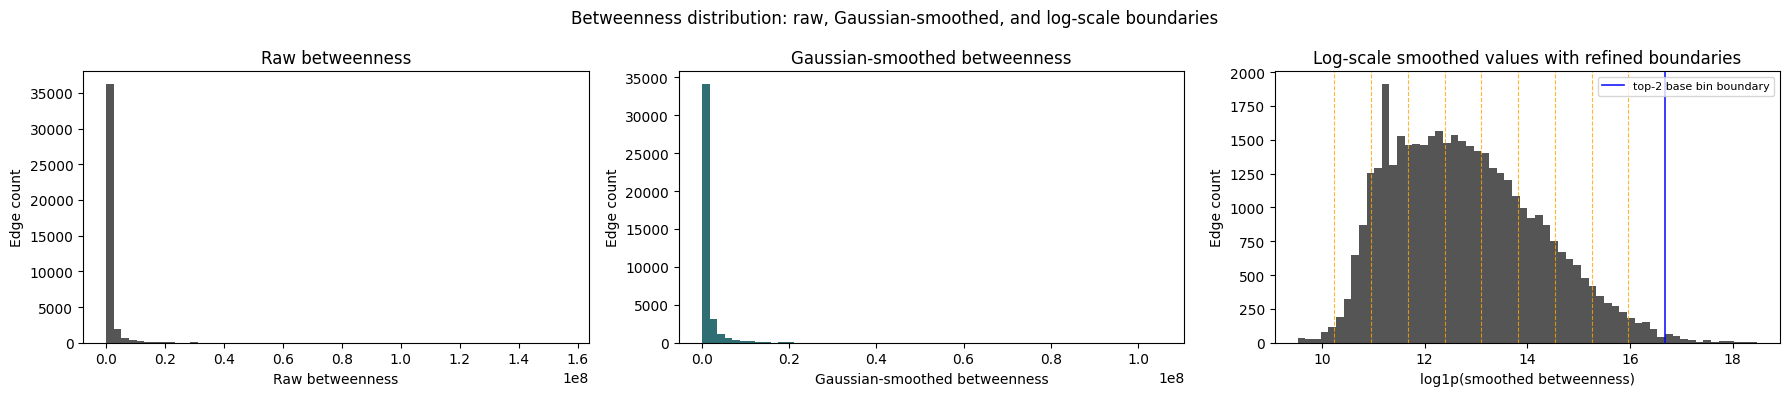

In [23]:
# ------------------------------------------------------------------
# PLOT: Raw vs Gaussian-smoothed betweenness distribution + step boundaries
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Left: raw betweenness (shows the heavy right skew)
axes[0].hist(raw_values, bins=60, color="#555555", edgecolor="none")
axes[0].set_xlabel("Raw betweenness")
axes[0].set_ylabel("Edge count")
axes[0].set_title("Raw betweenness")

# Middle: smoothed betweenness
axes[1].hist(smoothed_values, bins=60, color="#2f6f73", edgecolor="none")
axes[1].set_xlabel("Gaussian-smoothed betweenness")
axes[1].set_ylabel("Edge count")
axes[1].set_title("Gaussian-smoothed betweenness")

# Right: log1p-transformed smoothed values with refined step boundaries
axes[2].hist(log_values, bins=60, color="#555555", edgecolor="none")
for t in all_edges[1:-1]:
    color = "red" if t >= top2_lo else "orange"
    axes[2].axvline(t, color=color, linewidth=0.8, linestyle="--", alpha=0.8)
axes[2].axvline(top2_lo, color="blue", linewidth=1.2, linestyle="-", alpha=0.9,
                label="top-2 base bin boundary")
axes[2].set_xlabel("log1p(smoothed betweenness)")
axes[2].set_ylabel("Edge count")
axes[2].set_title("Log-scale smoothed values with refined boundaries")
axes[2].legend(fontsize=8)

plt.suptitle("Betweenness distribution: raw, Gaussian-smoothed, and log-scale boundaries", fontsize=12)
plt.tight_layout()
#plt.savefig("mde_betweenness_gaussian_smoothed_distribution.pdf")
plt.show()


## Gaussian smoothing note

`betweenness_smooth` is the value used to assign filtration steps. The original `betweenness` value is still kept on each edge in `H` for comparison. Increase `GAUSSIAN_SIGMA_HOPS` for stronger smoothing, or decrease it to stay closer to the original edge betweenness signal.


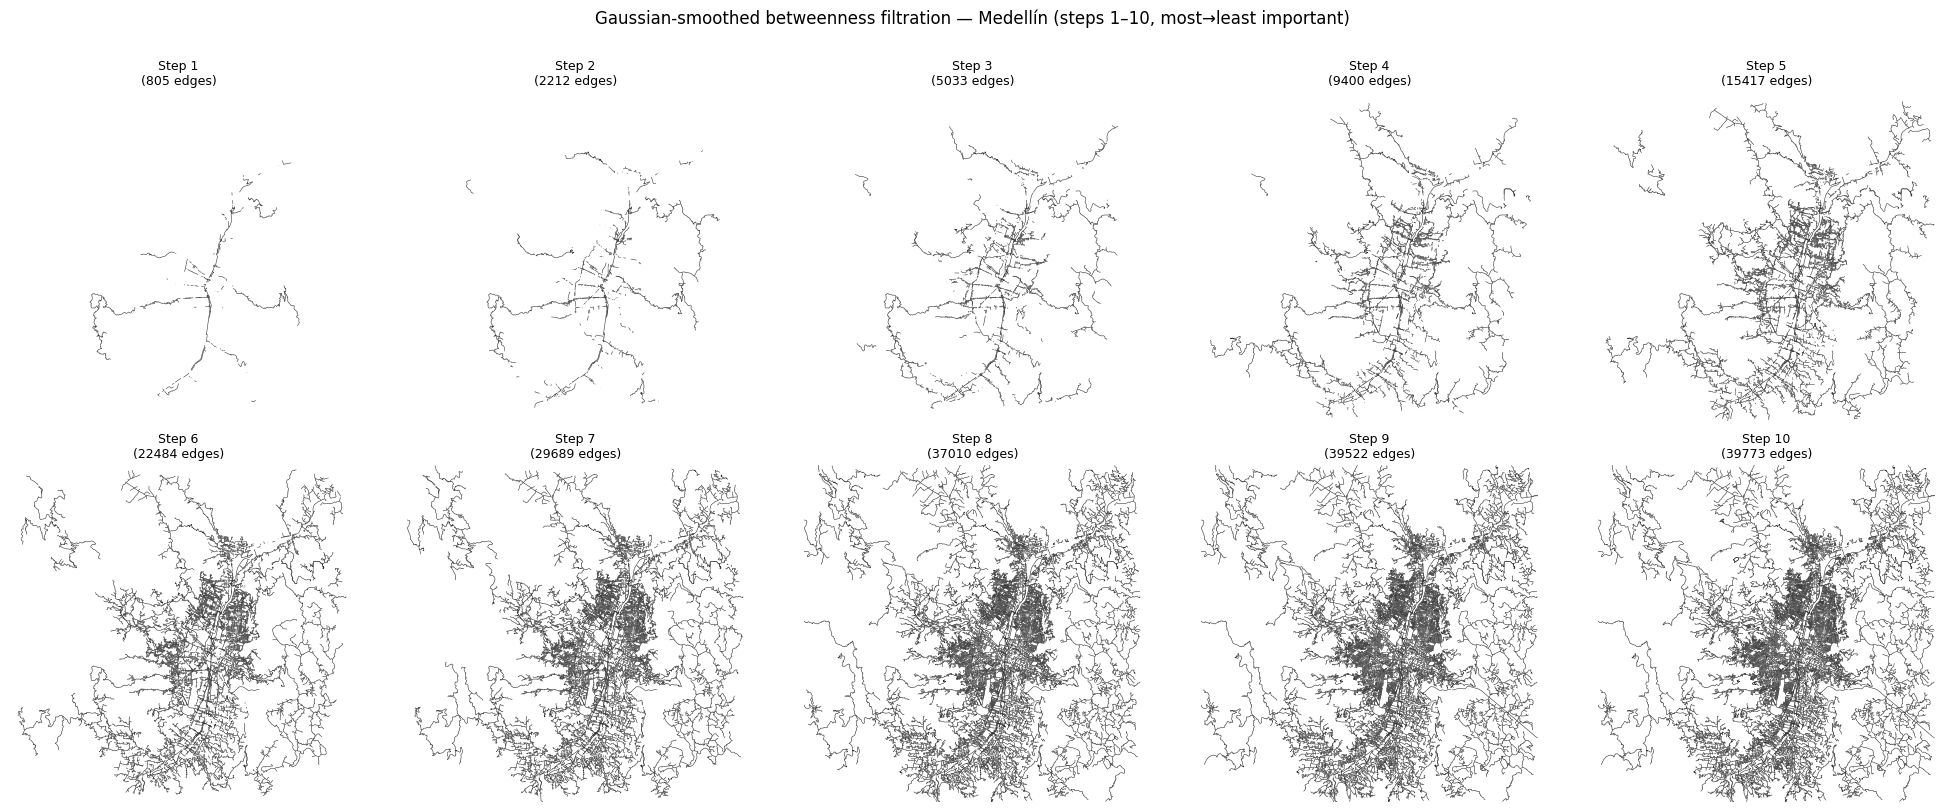

In [24]:
# ------------------------------------------------------------------
# PLOT: Cumulative filtration snapshots using OSMnx plot_graph
# Each panel shows all edges added up to that step.
# ------------------------------------------------------------------
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

cols = 5
rows = 2
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

xmin, ymin, xmax, ymax = edges_gdf.total_bounds

for step in range(1, N_STEPS + 1):
    ax = axes[step - 1]

    # Edges active at this step
    active_edges = {(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= step}

    # Filter the GeoDataFrame to active edges (match on u, v ignoring key)
    mask = edges_gdf.index.map(lambda idx: (idx[0], idx[1]) in active_edges)
    subset = edges_gdf[mask]

    if not subset.empty:
        subset.plot(ax=ax, linewidth=0.4, color="#333333")

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"Step {step}\n({len(active_edges)} edges)", fontsize=9)
    ax.set_axis_off()

plt.suptitle("Gaussian-smoothed betweenness filtration — Medellín (steps 1–10, most→least important)",
             fontsize=12, y=1.01)
plt.tight_layout()
#plt.savefig("mde_betweenness_gaussian_smoothed_filtration_snapshots.png")
plt.show()

In [25]:
# ------------------------------------------------------------------
# BUILD GUDHI SIMPLEX TREE
# All nodes at filtration 0; edges at their assigned step.
# ------------------------------------------------------------------
st = gudhi.SimplexTree()

node_to_int = {node: i for i, node in enumerate(H.nodes())}

for node in H.nodes():
    st.insert([node_to_int[node]], filtration=0.0)

for u, v, data in H.edges(data=True):
    st.insert([node_to_int[u], node_to_int[v]], filtration=float(data["filtration"]))

print("Simplex tree summary")
print("  Dimension  :", st.dimension())
print("  Num vertices:", st.num_vertices())
print("  Num simplices:", st.num_simplices())

Simplex tree summary
  Dimension  : 1
  Num vertices: 28729
  Num simplices: 68473


In [26]:
# ------------------------------------------------------------------
# COMPUTE PERSISTENCE
# ------------------------------------------------------------------
diag = st.persistence(homology_coeff_field=2, persistence_dim_max=True)

h0 = st.persistence_intervals_in_dimension(0)
h1 = st.persistence_intervals_in_dimension(1)

h1_finite = h1[np.isfinite(h1).all(axis=1)] if len(h1) > 0 else np.empty((0, 2))

print(f"H0 intervals: {len(h0)}")
print(f"H1 intervals: {len(h1)}  (finite: {len(h1_finite)})")

if len(h1_finite) > 0:
    h1_lengths = h1_finite[:, 1] - h1_finite[:, 0]
    print("\nFinite H1 bar lengths (sample):")
    print(h1_lengths[:20])

bettis = st.betti_numbers()
print("\nBetti numbers:", bettis)

H0 intervals: 28729
H1 intervals: 11016  (finite: 0)

Betti numbers: [1, 11016]


In [27]:
# ------------------------------------------------------------------
# Replace inf death values with N_STEPS + 1 for plotting
# ------------------------------------------------------------------
replacement = N_STEPS + 1
h0_plot = h0.copy()
h1_plot = h1.copy()
h0_plot[np.isinf(h0_plot)] = replacement
h1_plot[np.isinf(h1_plot)] = replacement

In [28]:
# ------------------------------------------------------------------
# GRAPH-THEORETIC DIAGNOSTICS
# ------------------------------------------------------------------
c = nx.number_connected_components(H)
m = H.number_of_edges()
n_nodes = H.number_of_nodes()
cycle_rank = m - n_nodes + c

print("Graph-theoretic diagnostics (full graph)")
print(f"  Nodes              : {n_nodes}")
print(f"  Edges              : {m}")
print(f"  Connected components: {c}")
print(f"  Cycle rank         : {cycle_rank}")

print("\nStep-by-step filtration summary")
for t in range(1, N_STEPS + 1):
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= t]
    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())
    G_t.add_edges_from(edges_t)
    n_t = G_t.number_of_nodes()
    m_t = G_t.number_of_edges()
    c_t = nx.number_connected_components(G_t)
    cr_t = m_t - n_t + c_t
    print(f"  Step {t:2d}: nodes={n_t}, edges={m_t:5d}, components={c_t:4d}, cycle_rank={cr_t}")

Graph-theoretic diagnostics (full graph)
  Nodes              : 28729
  Edges              : 39773
  Connected components: 1
  Cycle rank         : 11045

Step-by-step filtration summary
  Step  1: nodes=28729, edges=  805, components=27959, cycle_rank=35
  Step  2: nodes=28729, edges= 2212, components=26687, cycle_rank=170
  Step  3: nodes=28729, edges= 5033, components=24231, cycle_rank=535
  Step  4: nodes=28729, edges= 9400, components=20541, cycle_rank=1212
  Step  5: nodes=28729, edges=15417, components=15727, cycle_rank=2415
  Step  6: nodes=28729, edges=22484, components=10624, cycle_rank=4379
  Step  7: nodes=28729, edges=29689, components=5890, cycle_rank=6850
  Step  8: nodes=28729, edges=37010, components=1068, cycle_rank=9349
  Step  9: nodes=28729, edges=39522, components=  18, cycle_rank=10811
  Step 10: nodes=28729, edges=39773, components=   1, cycle_rank=11045


<Figure size 700x600 with 0 Axes>

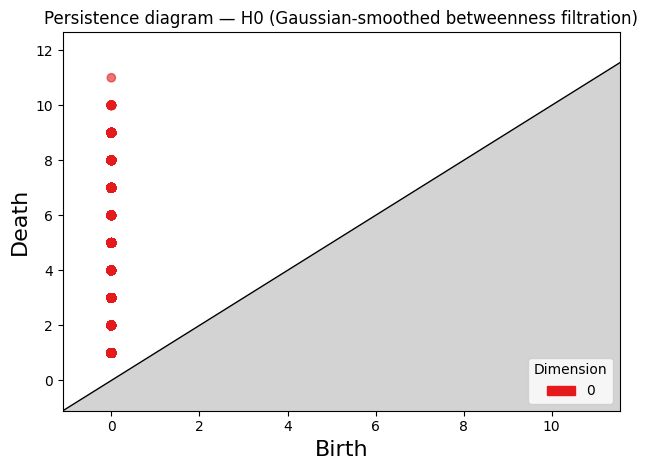

<Figure size 700x600 with 0 Axes>

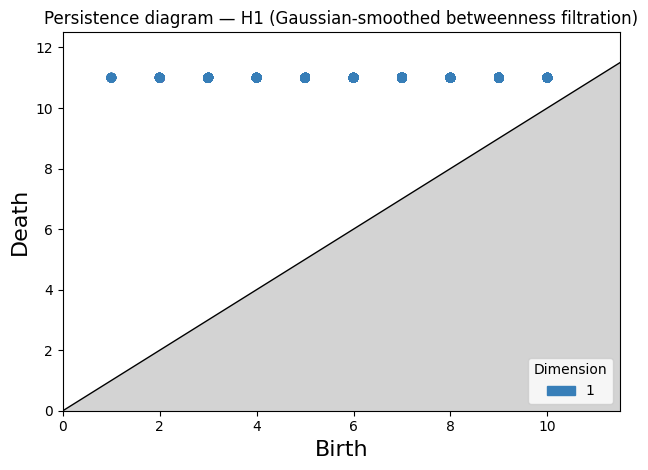

In [29]:
# ------------------------------------------------------------------
# PERSISTENCE DIAGRAMS — H0 and H1
# ------------------------------------------------------------------
if len(h0_plot) > 0:
    h0_diag = [(0, (b, d)) for b, d in h0_plot]
    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h0_diag)
    plt.title("Persistence diagram — H0 (Gaussian-smoothed betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_gaussian_smoothed_h0_diagram.pdf")
    plt.show()
else:
    print("No H0 intervals.")

if len(h1_plot) > 0:
    h1_diag = [(1, (b, d)) for b, d in h1_plot]
    plt.figure(figsize=(7, 6))
    gudhi.plot_persistence_diagram(h1_diag)
    plt.title("Persistence diagram — H1 (Gaussian-smoothed betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_gaussian_smoothed_h1_diagram.pdf")
    plt.show()
else:
    print("No H1 intervals.")

/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/gudhi/persistence_graphical_tools.py:107: UserWarning: There are 28729 intervals given as input, whereas max_intervals is set to 20000.
  warnings.warn(


<Figure size 1000x400 with 0 Axes>

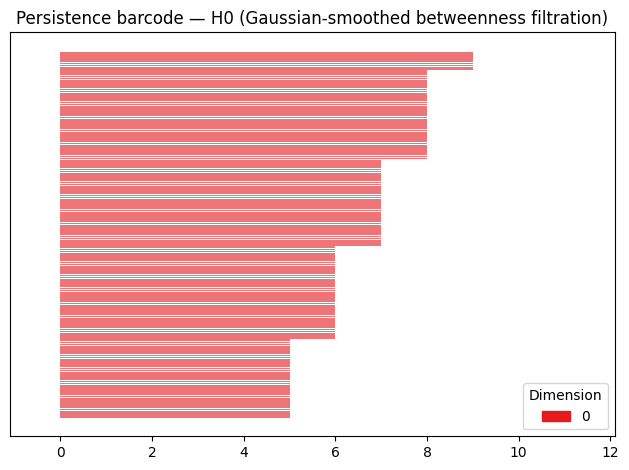

<Figure size 1000x400 with 0 Axes>

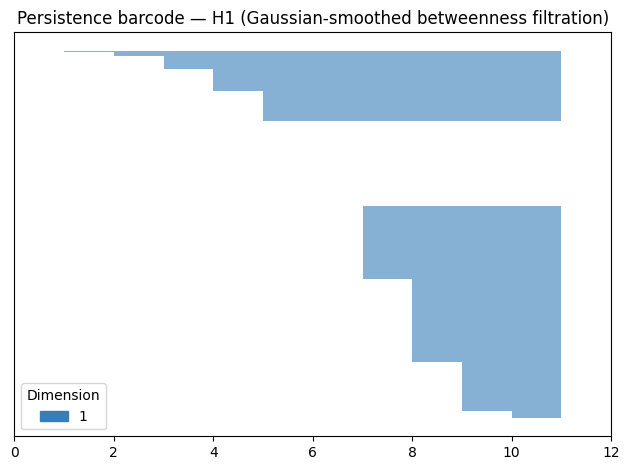

In [30]:
# ------------------------------------------------------------------
# PERSISTENCE BARCODES — H0 and H1
# ------------------------------------------------------------------
if len(h0_plot) > 0:
    h0_diag = [(0, (b, d)) for b, d in h0_plot]
    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h0_diag)
    plt.title("Persistence barcode — H0 (Gaussian-smoothed betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_gaussian_smoothed_h0_barcode.pdf")
    plt.show()

if len(h1_plot) > 0:
    h1_diag = [(1, (b, d)) for b, d in h1_plot]
    plt.figure(figsize=(10, 4))
    gudhi.plot_persistence_barcode(h1_diag)
    plt.title("Persistence barcode — H1 (Gaussian-smoothed betweenness filtration)")
    plt.tight_layout()
    #plt.savefig("mde_betweenness_gaussian_smoothed_h1_barcode.pdf")
    plt.show()

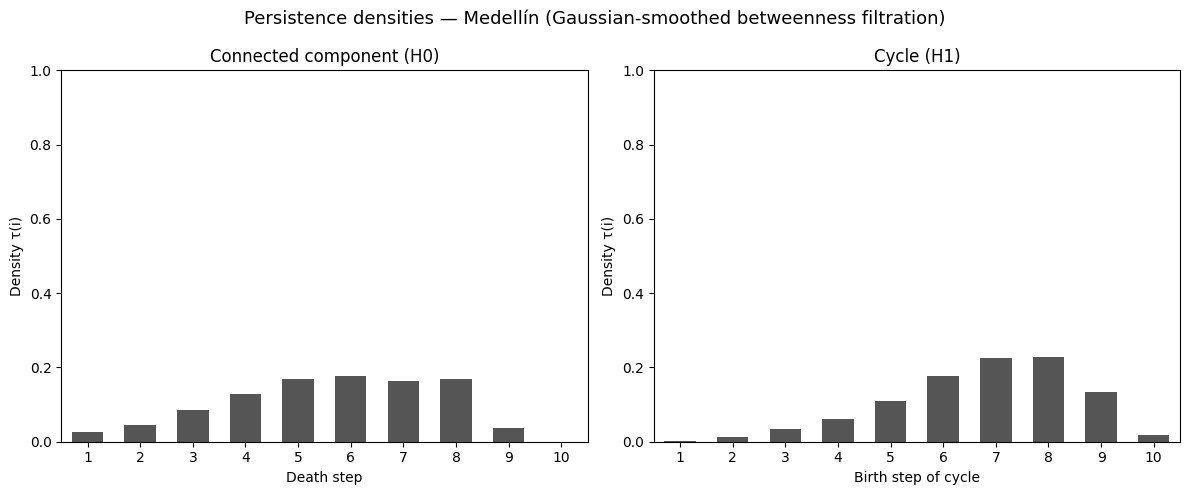

In [31]:
# ------------------------------------------------------------------
# PERSISTENCE DENSITY
# τ(i) = fraction of bars with persistence length == i
# H0: x-axis = death step (when component merges)
# H1: x-axis = birth step (when cycle appears), reversed so
#     leftmost bar = cycles born at the most-important step
# ------------------------------------------------------------------
def persistence_density(intervals, max_persistence=None):
    finite = intervals[np.isfinite(intervals).all(axis=1)] if len(intervals) > 0 else np.empty((0, 2))
    if len(finite) == 0:
        return np.array([]), np.array([])
    lengths = (finite[:, 1] - finite[:, 0]).astype(int)
    total = len(finite)
    if max_persistence is None:
        max_persistence = int(lengths.max())
    i_values = np.arange(1, max_persistence + 1)
    density = np.array([np.sum(lengths == i) / total for i in i_values])
    return i_values, density


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (intervals, label, dim) in zip(axes, [
    (h0_plot, "Connected component (H0)", "H0"),
    (h1_plot, "Cycle (H1)",               "H1"),
]):
    i_vals, dens = persistence_density(intervals, max_persistence=N_STEPS)

    if dim == "H1":
        dens = dens[::-1]  # reverse so step 1 = most important

    if len(i_vals) == 0:
        ax.set_title(f"No finite {dim} intervals")
        continue

    ax.bar(i_vals, dens, color="#555555", width=0.6)
    ax.set_xlim(0.5, N_STEPS + 0.5)
    ax.set_ylim(0, 1.0)
    ax.set_xticks(i_vals)
    ax.set_xlabel("Death step" if dim == "H0" else "Birth step of cycle")
    ax.set_ylabel("Density τ(i)")
    ax.set_title(label)

plt.suptitle("Persistence densities — Medellín (Gaussian-smoothed betweenness filtration)", fontsize=13)
plt.tight_layout()
#plt.savefig("mde_betweenness_gaussian_smoothed_density_7500_box.pdf")
plt.show()

In [32]:
dens

array([0.0031772 , 0.0122549 , 0.03313362, 0.06145606, 0.10911402,
       0.17828613, 0.22431009, 0.22685185, 0.13271605, 0.01870007])

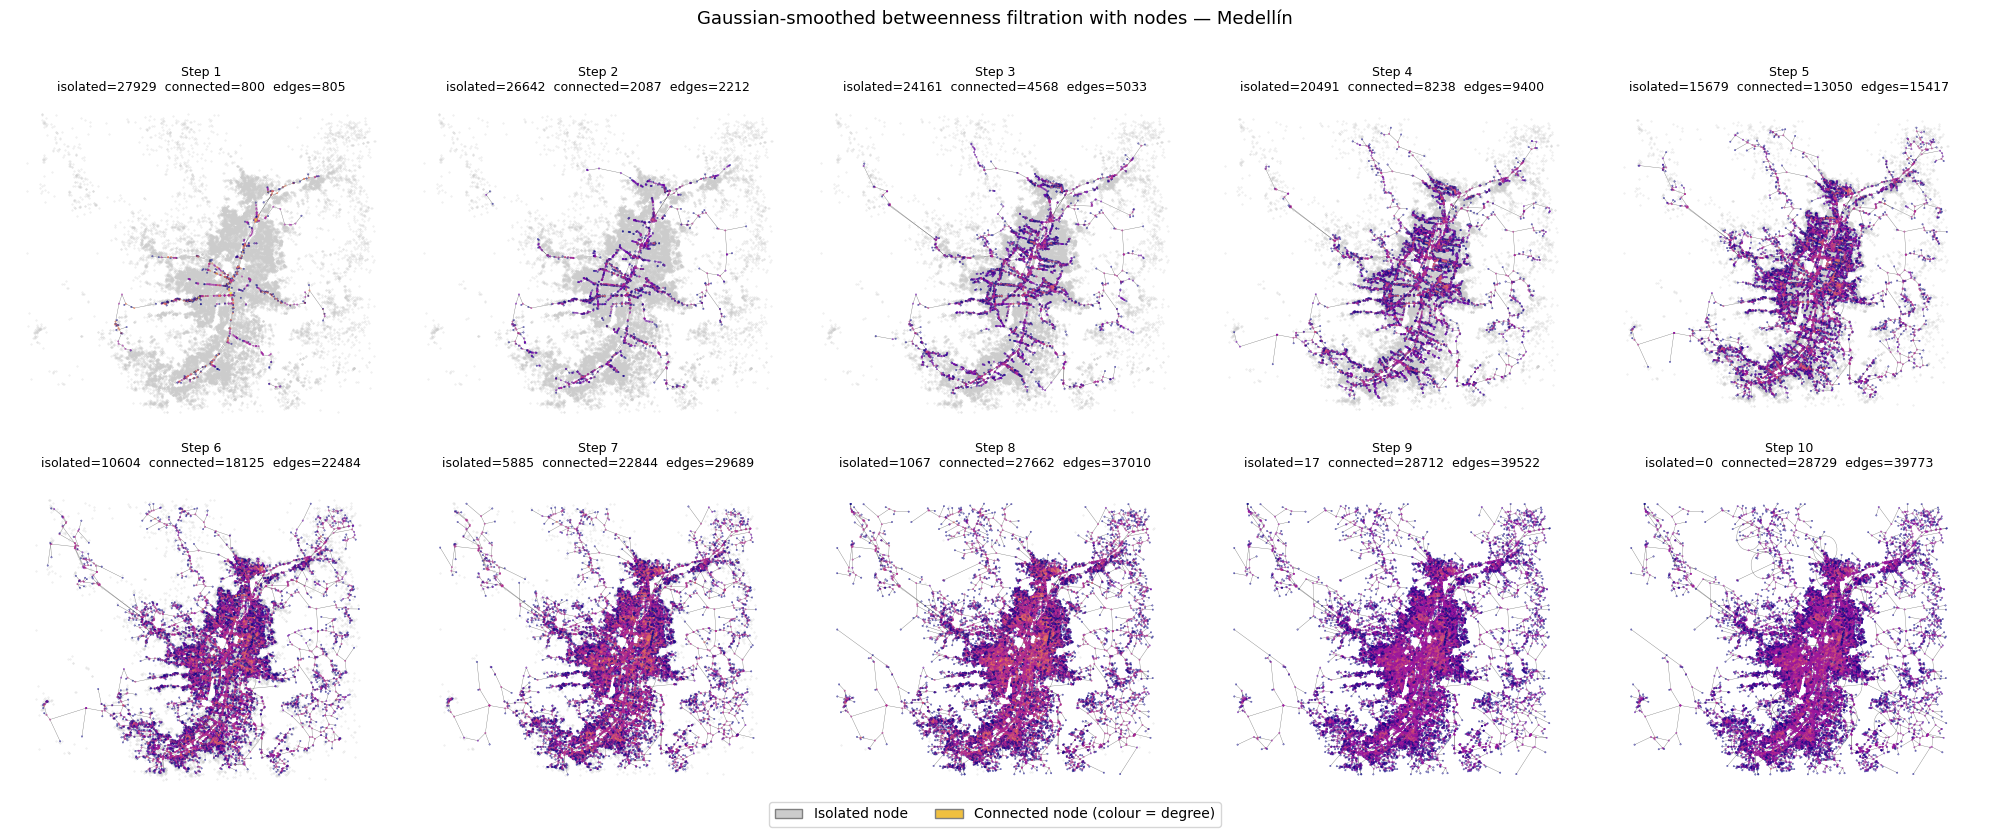

In [33]:
# ------------------------------------------------------------------
# FILTRATION PLOT WITH NODES — using OSMnx graph_to_gdfs for positions
# Node colour = degree at each step; isolated nodes shown in grey.
# ------------------------------------------------------------------
import matplotlib.patches as mpatches

# Node positions from OSMnx GeoDataFrame
pos = {node: (data["x"], data["y"]) for node, data in G.nodes(data=True)
       if "x" in data and "y" in data}

cols = 5
rows = 2
fig, axes = plt.subplots(rows, cols, figsize=(20, 8))
axes = axes.flatten()

for step in range(1, N_STEPS + 1):
    ax = axes[step - 1]
    edges_t = [(u, v) for u, v, d in H.edges(data=True) if d["filtration"] <= step]

    G_t = nx.Graph()
    G_t.add_nodes_from(H.nodes())
    G_t.add_edges_from(edges_t)

    degrees = dict(G_t.degree())
    isolated = [n for n, d in degrees.items() if d == 0 and n in pos]
    connected = [n for n, d in degrees.items() if d > 0 and n in pos]
    valid_edges = [(u, v) for u, v in G_t.edges() if u in pos and v in pos]

    nx.draw_networkx_edges(G_t, pos, edgelist=valid_edges, ax=ax,
                           edge_color="#333333", width=0.25, alpha=0.7)
    if isolated:
        nx.draw_networkx_nodes(G_t, pos, nodelist=isolated, ax=ax,
                               node_size=0.1, node_color="#cccccc", alpha=0.6)
    if connected:
        deg_vals = np.array([degrees[n] for n in connected], dtype=float)
        nx.draw_networkx_nodes(G_t, pos, nodelist=connected, ax=ax,
                               node_size=0.1, node_color=deg_vals,
                               cmap="plasma", alpha=0.9)

    ax.set_title(
        f"Step {step}\nisolated={len(isolated)}  connected={len(connected)}  edges={len(valid_edges)}",
        fontsize=9
    )
    ax.set_axis_off()

legend_handles = [
    mpatches.Patch(facecolor="#cccccc", edgecolor="grey", label="Isolated node"),
    mpatches.Patch(facecolor="#f0c040", edgecolor="grey", label="Connected node (colour = degree)"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
plt.suptitle("Gaussian-smoothed betweenness filtration with nodes — Medellín", fontsize=13, y=1.01)
plt.tight_layout()
#plt.savefig("mde_betweenness_gaussian_smoothed_with_nodes_filt.pdf")
plt.show()